In [1]:
!pip install dowhy econml lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.3 MB 505.1 kB/s eta 0:00:04
   ------------- -------------------------- 0.8/2.3 MB 674.0 kB/s eta 0:00:03
   ------------------ --------------------- 1.0/2.3 MB 790.2 kB/s eta 0:00:02
   ------------------ --------------------- 1.0/2.3 MB 790.2 kB/s eta 0:00:02
   ------------------ --------------------- 1.0/2.3 MB 790.2 kB/s eta 0:00:02
   ------------------ --------------------- 1.0/2.3 MB 790.2 kB/s eta 0:00:02
   --------------------------- ------------ 1.6/2.3 MB 688.7 kB/s eta 0:00:02
   --------------------------- ------------ 1.6/2.3 MB 688.7 kB/s eta 0:00:02
   -------------------

In [2]:
import pandas as pd, numpy as np

df = pd.read_csv("hillstrom.csv")
df["treatment"] = (df["segment"] != "No E-Mail").astype(int)
df = df.drop(columns=["history_segment", "segment"])
df = pd.get_dummies(df, columns=["zip_code", "channel"], drop_first=True, dtype=int)

confounders = [c for c in df.columns if c not in ["treatment", "visit", "conversion", "spend"]]
print(confounders)
print(df["treatment"].value_counts())

['recency', 'history', 'mens', 'womens', 'newbie', 'zip_code_Surburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']
treatment
1    42694
0    21306
Name: count, dtype: int64


In [3]:
from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment="treatment",
    outcome="conversion",
    common_causes=confounders
)

estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[conversion|channel_Phone,mens,womens,channel_Web,zip_code_Surbu ↪
d[treatment]                                                                   ↪

↪                                             
↪ rban,recency,zip_code_Urban,newbie,history])
↪                                             
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→conversion then P(conversion|treatment,channel_Phone,mens,womens,channel_Web,zip_code_Surburban,recency,zip_code_Urban,newbie,history,U) = P(conversion|treatment,channel_Phone,mens,womens,channel_Web,zip_code_Surburban,recency,zip_code_Urban,newbie,history)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!



In [1]:
import networkx as nx
nx.algorithms.d_separated = nx.algorithms.is_d_separator

In [4]:
print(df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df.describe())
print("Conversion rate:", df["conversion"].mean())

(64000, 13)
Missing values:
 recency               0
history               0
mens                  0
womens                0
newbie                0
visit                 0
conversion            0
spend                 0
treatment             0
zip_code_Surburban    0
zip_code_Urban        0
channel_Phone         0
channel_Web           0
dtype: int64
Duplicate rows: 6988
            recency       history          mens        womens        newbie  \
count  64000.000000  64000.000000  64000.000000  64000.000000  64000.000000   
mean       5.763734    242.085656      0.551031      0.549719      0.502250   
std        3.507592    256.158608      0.497393      0.497526      0.499999   
min        1.000000     29.990000      0.000000      0.000000      0.000000   
25%        2.000000     64.660000      0.000000      0.000000      0.000000   
50%        6.000000    158.110000      1.000000      1.000000      1.000000   
75%        9.000000    325.657500      1.000000      1.000000      1.000

In [6]:
import statsmodels.api as sm

Xc = sm.add_constant(df[["treatment"] + confounders].astype(float))
ols = sm.OLS(df["conversion"].astype(float), Xc).fit()
print("Average Treatment Effect:", ols.params["treatment"])
print("p-value:", ols.pvalues["treatment"])

Average Treatment Effect: 0.004939857438799675
p-value: 4.623834970157697e-10


In [7]:
from econml.dml import LinearDML
from lightgbm import LGBMRegressor, LGBMClassifier

Y = df["conversion"].values
T = df["treatment"].values
X = df[confounders].astype(float).values

dml = LinearDML(
    model_y=LGBMRegressor(n_estimators=100, verbose=-1),
    model_t=LGBMClassifier(n_estimators=100, verbose=-1),
    discrete_treatment=True,
    random_state=42
)
dml.fit(Y, T, X=X)

df["ITE"] = dml.effect(X)
print("DML Average Treatment Effect:", df["ITE"].mean())
print(df["ITE"].describe())

DML Average Treatment Effect: 0.004980021615338001
count    64000.000000
mean         0.004980
std          0.002918
min         -0.000585
25%          0.002919
50%          0.004637
75%          0.006489
max          0.019263
Name: ITE, dtype: float64


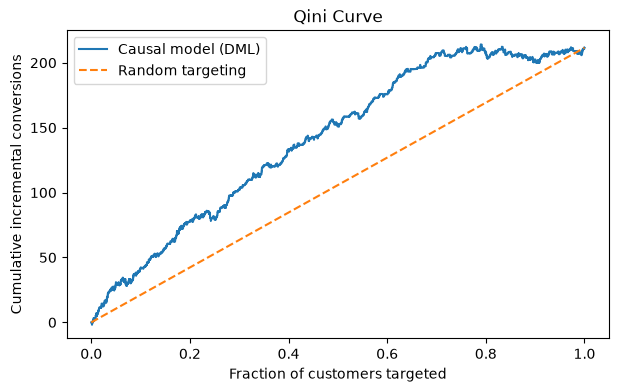

In [8]:
import numpy as np
import matplotlib.pyplot as plt

order = np.argsort(-df["ITE"].values)
y = df["conversion"].values[order]
t = df["treatment"].values[order]

nt = np.cumsum(t)
nc = np.cumsum(1 - t)
yt = np.cumsum(y * t)
yc = np.cumsum(y * (1 - t))
qini = yt - yc * np.where(nc > 0, nt / np.maximum(nc, 1), 0)

x = np.arange(1, len(y) + 1) / len(y)
plt.figure(figsize=(7, 4))
plt.plot(x, qini, label="Causal model (DML)")
plt.plot([0, 1], [0, qini[-1]], "--", label="Random targeting")
plt.xlabel("Fraction of customers targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini Curve")
plt.legend()
plt.show()

In [9]:
rng = np.random.default_rng(42)
T_fake = rng.permutation(T)

dml_placebo = LinearDML(
    model_y=LGBMRegressor(n_estimators=100, verbose=-1),
    model_t=LGBMClassifier(n_estimators=100, verbose=-1),
    discrete_treatment=True,
    random_state=42
)
dml_placebo.fit(Y, T_fake, X=X)
print("Placebo ATE (should be ~0):", dml_placebo.effect(X).mean())
print("Real ATE:", df["ITE"].mean())

Placebo ATE (should be ~0): 0.0007530317627650581
Real ATE: 0.004980021615338001


In [11]:
from scipy.optimize import linprog

cost_per_email = 0.10
budget = 1000
value = df.loc[df["conversion"] == 1, "spend"].mean()

gain = df["ITE"].values * value - cost_per_email
res = linprog(
    c=-gain,
    A_ub=[np.full(len(df), cost_per_email)],
    b_ub=[budget],
    bounds=(0, 1),
    method="highs"
)
df["send_email"] = (res.x > 0.5).astype(int)

n = df["send_email"].sum()
opt_gain = (df.loc[df["send_email"] == 1, "ITE"] * value).sum()
rand_gain = df["ITE"].mean() * value * n
print("Customers selected:", n)
print("Expected extra revenue (optimized): $", round(opt_gain, 2))
print("Expected extra revenue (random targeting): $", round(rand_gain, 2))

Customers selected: 10000
Expected extra revenue (optimized): $ 11811.65
Expected extra revenue (random targeting): $ 5794.93


In [12]:
saving = opt_gain - rand_gain
print(f"This strategy earns ${saving:.2f} more than random targeting with the same ${budget} budget.")

This strategy earns $6016.72 more than random targeting with the same $1000 budget.


In [13]:
from scipy.stats import ks_2samp

half = len(df) // 2
old, new = df.iloc[:half], df.iloc[half:]
for col in ["recency", "history"]:
    stat, p = ks_2samp(old[col], new[col])
    print(col, "-> DRIFT WARNING" if p < 0.05 else "-> stable", "(p =", round(p, 4), ")")

recency -> stable (p = 0.9735 )
history -> stable (p = 0.9825 )


In [15]:
cols = ["recency", "history", "mens", "womens", "newbie", "treatment", "conversion", "ITE"]
df[cols].to_csv("ite_scores.csv", index=False)
print("Saved ite_scores.csv")

Saved ite_scores.csv


In [16]:
%%writefile app.py
import streamlit as st, pandas as pd, numpy as np
import plotly.express as px, plotly.graph_objects as go

st.set_page_config(page_title="EconoCausal", layout="wide")
st.title("EconoCausal: Causal Uplift & Budget Allocation")

up = st.sidebar.file_uploader("Upload ITE scores CSV", type="csv")
df = pd.read_csv(up) if up else pd.read_csv("ite_scores.csv")
budget = st.sidebar.number_input("Budget ($)", 100, 100000, 1000, 100)
cost = st.sidebar.number_input("Cost per email ($)", 0.01, 5.0, 0.10, 0.01)
value = st.sidebar.number_input("Revenue per conversion ($)", 1.0, 500.0, 116.0, 1.0)
lo, hi = int(df.recency.min()), int(df.recency.max())
r = st.sidebar.slider("Recency (months)", lo, hi, (lo, hi))
f = df[df.recency.between(*r)]

c1, c2 = st.columns(2)
c1.metric("Customers", f"{len(f):,}")
c2.metric("Average ITE", f"{f.ITE.mean():.5f}")

st.plotly_chart(px.histogram(f, x="ITE", nbins=50, title="ITE distribution"), use_container_width=True)

o = f.sort_values("ITE", ascending=False)
y, t = o.conversion.values, o.treatment.values
nt, nc = np.cumsum(t), np.cumsum(1 - t)
q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.where(nc > 0, nt / np.maximum(nc, 1), 0)
x = np.arange(1, len(y) + 1) / len(y)
fig = go.Figure()
fig.add_scatter(x=x, y=q, name="Causal model")
fig.add_scatter(x=[0, 1], y=[0, q[-1]], name="Random", line=dict(dash="dash"))
fig.update_layout(title="Qini / Uplift curve", xaxis_title="Fraction targeted", yaxis_title="Incremental conversions")
st.plotly_chart(fig, use_container_width=True)

n = int(budget / cost)
alloc = o.head(n)
opt = (alloc.ITE * value).sum()
rnd = f.ITE.mean() * value * len(alloc)
st.success(f"This strategy earns ${opt - rnd:,.2f} more than random targeting with the same ${budget:,} budget.")
st.subheader("Allocation: customers to email")
st.dataframe(alloc.head(100))

Writing app.py
